In [1]:
!pip install pyfixest[jax]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.7/115.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.2/607.2 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00


In [2]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 2.0 MB/s eta 0:00:00


In [3]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [4]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0065
Estimator:                   PanelOLS   R-squared (Between):              0.0025
No. Observations:                6214   R-squared (Within):            8.848e-05
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0063
Time:                        04:48:31   Log-likelihood                -5.787e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      3.6793
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                 F(11,6148)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             26.460
                            

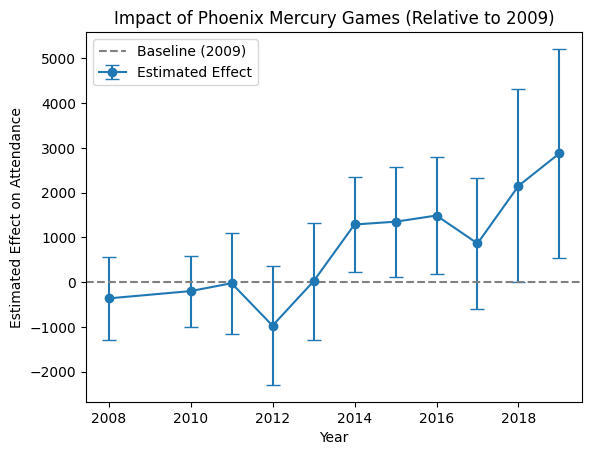

In [5]:
# Phoenix Mercury (DeWanna Bonner; 2009-2019)
px_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Mercury Games (2009-2019)
px_attendance_df['PX_Mercury_Game'] = (px_attendance_df['Home Team'] == 'Phoenix Mercury') & (px_attendance_df['Year'].between(2008, 2019))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2009 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]:
    col_name = f'INX{year}'
    px_attendance_df[col_name] = px_attendance_df['PX_Mercury_Game'].astype(int)
    px_attendance_df.loc[px_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
px_attendance_df = px_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2008 + INX2010 + INX2011 + INX2012 + INX2013 + INX2014 + INX2015 + INX2016 + INX2017 + INX2018 + INX2019 + EntityEffects + TimeEffects - TimeEffects[2009]',
    px_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]  # Excluding 2009 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2009)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Phoenix Mercury Games (Relative to 2009)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0122
Estimator:                   PanelOLS   R-squared (Between):              0.0055
No. Observations:                6214   R-squared (Within):              -0.0125
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0123
Time:                        04:48:32   Log-likelihood                -5.785e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      6.8839
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                 F(11,6148)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             168.01
                            

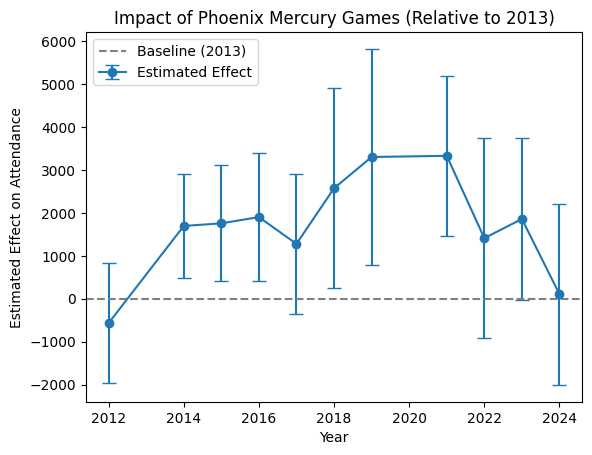

In [6]:
# Phoenix Mercury (Brittney Griner; 2013-2024)
px_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Mercury Games (2013-2024)
px_attendance_df['PX_Mercury_Game'] = (px_attendance_df['Home Team'] == 'Phoenix Mercury') & (px_attendance_df['Year'].between(2012, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2013 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2012, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    px_attendance_df[col_name] = px_attendance_df['PX_Mercury_Game'].astype(int)
    px_attendance_df.loc[px_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
px_attendance_df = px_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2012 + INX2014 + INX2015 + INX2016 + INX2017 + INX2018 + INX2019 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2013]',
    px_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2012, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]  # Excluding 2013 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2013)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Phoenix Mercury Games (Relative to 2013)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0044
Estimator:                   PanelOLS   R-squared (Between):              0.0015
No. Observations:                6214   R-squared (Within):              -0.0087
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0028
Time:                        04:48:32   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      13.627
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(2,6157)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             7.2930
                            

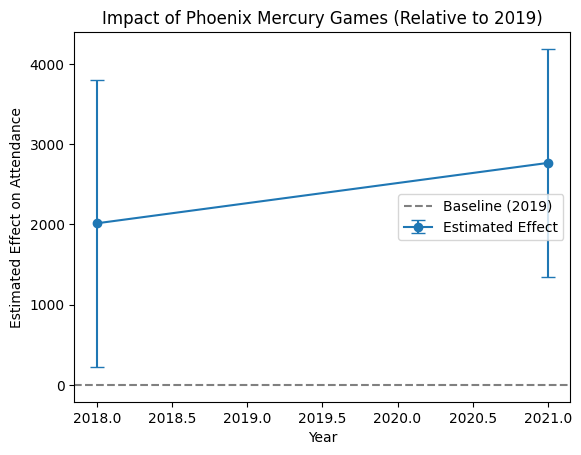

In [7]:
# Phoenix Mercury (Alanna Smith; 2019-2021)
px_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Mercury Games (2019-2021)
px_attendance_df['PX_Mercury_Game'] = (px_attendance_df['Home Team'] == 'Phoenix Mercury') & (px_attendance_df['Year'].between(2018, 2021))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2019 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2018, 2021]:
    col_name = f'INX{year}'
    px_attendance_df[col_name] = px_attendance_df['PX_Mercury_Game'].astype(int)
    px_attendance_df.loc[px_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
px_attendance_df = px_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2018 + INX2021 + EntityEffects + TimeEffects - TimeEffects[2019]',
    px_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2018, 2021]  # Excluding 2019 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2019)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Phoenix Mercury Games (Relative to 2019)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0047
Estimator:                   PanelOLS   R-squared (Between):              0.0018
No. Observations:                6214   R-squared (Within):              -0.0098
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0034
Time:                        04:50:53   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      9.6626
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(3,6156)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             7.5836
                            

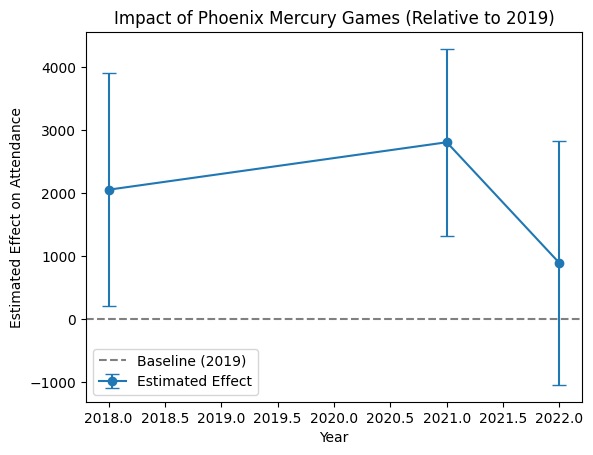

In [13]:
# Phoenix Mercury (Skylar Diggins-Smith; 2020-2023)
px_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Mercury Games (2020-2022; she did not play in 2023 due to maternity leave)
px_attendance_df['PX_Mercury_Game'] = (px_attendance_df['Home Team'] == 'Phoenix Mercury') & (px_attendance_df['Year'].between(2018, 2022))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2019 as the Reference (since there were no games in 2020)); no data for 2020 (COVID year) so I will also omit it)
for year in [2018, 2021, 2022]:
    col_name = f'INX{year}'
    px_attendance_df[col_name] = px_attendance_df['PX_Mercury_Game'].astype(int)
    px_attendance_df.loc[px_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
px_attendance_df = px_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2018 + INX2021 + INX2022 + EntityEffects + TimeEffects - TimeEffects[2019]',
    px_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2018, 2021, 2022]  # Excluding 2019 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2019)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Phoenix Mercury Games (Relative to 2019)")
plt.legend()
plt.show()
